In [1]:
import s3fs
import numpy as np
import zarr

BUCKET = "simulations"
DS = "flow_export/A1"

fs = s3fs.S3FileSystem(profile='default', client_kwargs={'endpoint_url':'http://localhost:8333'})
def _axis(n):
    return np.asarray(zarr.open_array(
        store=s3fs.S3Map(root=f"{BUCKET}/{DS}/channel.zarr/{n}", s3=fs),
        mode="r",
    ))
x, y, z = _axis("x"), _axis("y"), _axis("z")
za = zarr.open_array(
    store=s3fs.S3Map(root=f"{BUCKET}/{DS}/data.zarr", s3=fs),
    mode="r",
)


In [2]:
za

<zarr.core.Array (4001, 5, 128, 129, 128) float32 read-only>

In [3]:
data = za[400::100]

In [4]:
nx = len(x)
dx = x[1] - x[0]
kx = np.fft.fftfreq(nx, dx) * 2 * np.pi
nz = len(z)
dz = z[1] - z[0]
kz = np.fft.fftfreq(nz, dz) * 2 * np.pi

In [5]:
data_hat = np.fft.fftn(data, axes=(2, 4))

In [10]:
energy = (abs(data_hat) ** 2).real

In [11]:
energy_tavg = energy.mean(0)

In [12]:
energy_tavg.shape

(5, 128, 129, 128)

In [36]:
def yp_to_yn(yp):
    for i in range(len(y) - 1):
        cur = y[i] * 200
        nex = y[i + 1] * 200
        if cur <= yp < nex:
            if yp - cur < nex - yp:
                return i
            else:
                return i + 1
        else:
            continue

In [37]:
yp_to_yn(15)

13

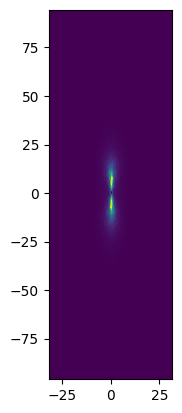

In [59]:
import matplotlib.pyplot as plt
Lx = nx * dx
Lz = nz * dz
P = energy_tavg[0, :, 13, :]
P[0, 0] = 0
plt.imshow(
    np.fft.fftshift(P).T,
    extent=(kx.min(), kx.max(),
            kz.min(), kz.max()),
    aspect="equal",
    origin="lower",
)
plt.show()

np.float64(4.19)